# モーザーの円分割問題

**問題**：円周上に $n$ 個の点をとり，すべての2点を線分（弦）で結ぶ。円の内部は最大でいくつの領域に分かれるか。

「最大」とは，3本以上の弦が円の内部の1点で交わらないように点を置く（**一般の位置**にある）ということです。

$n = 1, 2, 3, 4, 5$ と調べると領域の数は

$$1,\ 2,\ 4,\ 8,\ 16$$

となり，$2^{n-1}$ に見えます。ところが $n=6$ では 32 ではなく **31** になります。
「小さい場合の規則性を信じてはいけない」例としてよく知られた問題で，Leo Moser の名前で呼ばれています。

このノートブックでは
1. 図をかいて確かめる
2. 公式 $\displaystyle R(n) = \binom{n}{4} + \binom{n}{2} + 1$ を導く
3. 交点を実際に計算して領域を数え，公式と一致するか確かめる
4. 正 $n$ 角形の頂点に点をとると，3本以上の弦が1点で交わって領域が減ることを見る

を行います。

## 1. 図をかく

点を円周上に「でたらめに」置くと，ほぼ確実に一般の位置になります。
ここでは等間隔の位置から少しずらして置きます（等間隔のままだと，$n=6$ で3本の対角線が中心で交わってしまいます）。

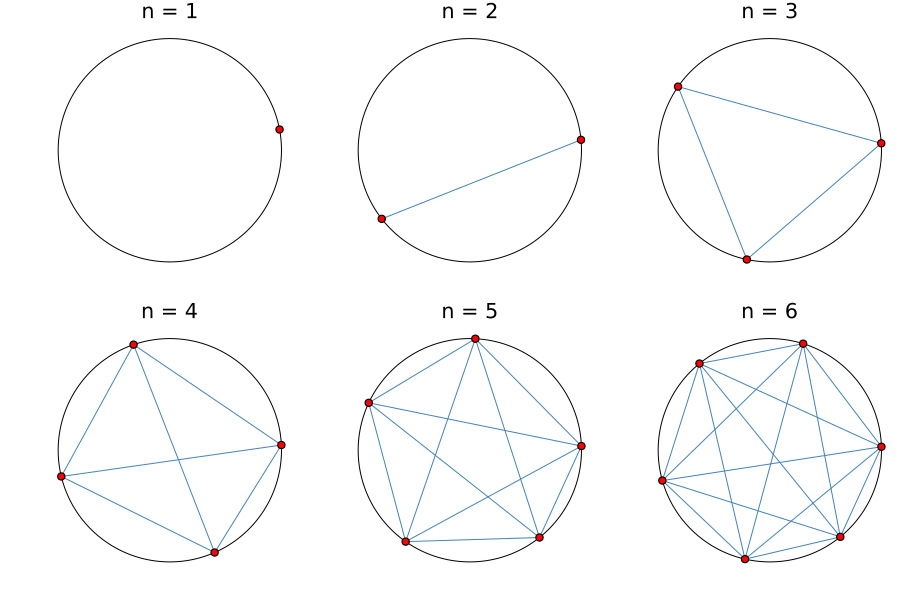

In [1]:
using Plots, Random

# 円周上の n 点の角度：等間隔から少しずらす（一般の位置にするため）
function angles(n; seed = 1, jitter = 0.3)
    rng = MersenneTwister(seed)
    sort([2π * (k + jitter * rand(rng)) / n for k in 0:n-1])
end

function drawchords(θ; title = "")
    t = range(0, 2π, length = 200)
    p = plot(cos.(t), sin.(t), color = :black, aspect_ratio = 1, legend = false,
             axis = false, grid = false, title = title)
    n = length(θ)
    for i in 1:n, j in i+1:n
        plot!(p, [cos(θ[i]), cos(θ[j])], [sin(θ[i]), sin(θ[j])], color = :steelblue)
    end
    scatter!(p, cos.(θ), sin.(θ), color = :red, markersize = 4)
    return p
end

plot([drawchords(angles(n), title = "n = $n") for n in 1:6]..., layout = (2, 3), size = (900, 600))

## 2. 公式を導く

### 弦を1本ずつ引いていく

最初は円の内部が 1 つの領域です。弦を1本ずつ引いていきます。

新しく引く弦が，すでに引いた弦と $k$ 個の点で交わるとき，その弦は $k+1$ 個の部分に分かれ，**各部分がそれぞれ1つの領域を2つに分けます**。
したがって領域は $k+1$ 増えます。

すべての弦を引き終わると

$$
R(n) = 1 + \underbrace{(\text{弦の本数})}_{\text{各弦の「+1」}} + \underbrace{(\text{交点の個数})}_{\text{各交点の「+1」}}
$$

となります（各交点は，その交点を通る2本の弦のうち後から引いたほうで1回だけ数えられます）。

### 弦の本数と交点の個数

- 弦の本数は，$n$ 点から2点を選ぶ数なので $\dbinom{n}{2}$。
- 円の内部の交点は，**円周上の4点を選ぶごとにちょうど1つ**できます。4点 $A, B, C, D$（円周上の順）を選ぶと，交わる弦の組は対角線 $AC$ と $BD$ だけだからです。一般の位置なので，異なる4点の組が同じ交点を与えることはありません。よって交点は $\dbinom{n}{4}$ 個。

以上から

$$
\boxed{\,R(n) = \binom{n}{4} + \binom{n}{2} + 1\,}
$$

### オイラーの公式でも確かめる

円周上の点と内部の交点を頂点，弦の各部分と円弧を辺とする平面グラフを考えます。

- 頂点：$V = n + \dbinom{n}{4}$
- 辺：交点1つにつき2本の弦がそれぞれ1回ずつ分断されるので，弦の部分は $\dbinom{n}{2} + 2\dbinom{n}{4}$ 本。円弧が $n$ 本あるので $E = n + \dbinom{n}{2} + 2\dbinom{n}{4}$
- オイラーの公式 $V - E + F = 2$ で，$F$ には円の外側の領域も1つ含まれるので，内部の領域は

$$
F - 1 = E - V + 1 = \binom{n}{4} + \binom{n}{2} + 1
$$

と同じ結果になります。

## 3. なぜ $2^{n-1}$ に見えるのか

$\binom{n}{4} + \binom{n}{2} + 1$ は，パスカルの三角形の $n-1$ 段目の**最初の5つの和**に書き直せます：

$$
R(n) = \binom{n-1}{0} + \binom{n-1}{1} + \binom{n-1}{2} + \binom{n-1}{3} + \binom{n-1}{4}.
$$

（$\binom{n}{2} = \binom{n-1}{1} + \binom{n-1}{2}$，$\binom{n}{4} = \binom{n-1}{3} + \binom{n-1}{4}$ を使います。）

一方 $2^{n-1}$ は $n-1$ 段目の**全部の和**です。$n-1 \le 4$，つまり $n \le 5$ のときは段に5つ以下しか数がないので両者は一致しますが，$n = 6$ からは $\binom{n-1}{5}$ 以降の分だけ $R(n)$ が小さくなります。
$n = 6$ では $2^5 - R(6) = \binom{5}{5} = 1$ で，32 と 31 の差はちょうど 1 です。

In [2]:
R(n) = binomial(n, 4) + binomial(n, 2) + 1

println(" n   R(n)   2^(n-1)   パスカル5項の和")
for n in 1:15
    s = sum(binomial(n - 1, k) for k in 0:4)
    println(lpad(n, 2), lpad(R(n), 7), lpad(2^(n - 1), 10), lpad(s, 12))
end

 n   R(n)   2^(n-1)   パスカル5項の和
 1      1         1           1
 2      2         2           2
 3      4         4           4
 4      8         8           8
 5     16        16          16
 6     31        32          31
 7     57        64          57
 8     99       128          99
 9    163       256         163
10    256       512         256
11    386      1024         386
12    562      2048         562
13    794      4096         794
14   1093      8192        1093
15   1471     16384        1471


## 4. 交点を実際に計算して領域を数える

公式を使わずに，弦どうしの交点を座標で計算し，オイラーの公式 $(\text{内部の領域}) = E - V + 1$ で領域を数えます。

- 円周上の点に番号 $1, \ldots, n$ を円周の順につけると，弦 $(i, j)$ と $(k, l)$（$i<j$，$k<l$）が内部で交わるのは，端点が交互に並ぶ $i<k<j<l$ または $k<i<l<j$ のとき。
- 交点の座標は丸めて辞書に入れ，同じ点は1つにまとめます（正多角形のように3本以上が1点で交わる場合にも数えられるように）。
- 各弦について，その上にある異なる交点が $m$ 個なら，弦は $m+1$ 本の辺に分かれます。

In [3]:
# 円周上の角度 θ（昇順）の点を結んだときの，円の内部の領域の数
function countregions(θ; digits = 9)
    n = length(θ)
    P = [(cos(t), sin(t)) for t in θ]
    chords = [(i, j) for i in 1:n for j in i+1:n]
    onchord = Dict(c => Set{NTuple{2,Float64}}() for c in chords)   # 各弦の上の交点
    for a in 1:length(chords), b in a+1:length(chords)
        (i, j), (k, l) = chords[a], chords[b]
        (i < k < j < l || k < i < l < j) || continue
        # 線分 P[i]P[j] と P[k]P[l] の交点
        (x1, y1), (x2, y2), (x3, y3), (x4, y4) = P[i], P[j], P[k], P[l]
        den = (x1 - x2) * (y3 - y4) - (y1 - y2) * (x3 - x4)
        s = ((x1 - x3) * (y3 - y4) - (y1 - y3) * (x3 - x4)) / den
        q = round.((x1 + s * (x2 - x1), y1 + s * (y2 - y1)), digits = digits) .+ 0.0  # -0.0 を 0.0 にそろえる
        push!(onchord[chords[a]], q)
        push!(onchord[chords[b]], q)
    end
    inner = union(Set{NTuple{2,Float64}}(), values(onchord)...)
    V = n + length(inner)
    E = n + sum(length(s) + 1 for s in values(onchord); init = 0)
    return E - V + 1
end

println(" n  数えた値  公式 R(n)")
for n in 1:15
    c = countregions(angles(n))
    println(lpad(n, 2), lpad(c, 9), lpad(R(n), 10), c == R(n) ? "" : "  ← 不一致")
end

 n  数えた値  公式 R(n)
 1        1         1
 2        2         2
 3        4         4
 4        8         8
 5       16        16
 6       31        31
 7       57        57
 8       99        99
 9      163       163
10      256       256
11      386       386
12      562       562
13      794       794
14     1093      1093
15     1471      1471


## 5. 正 $n$ 角形の頂点にとると

点を等間隔（正 $n$ 角形の頂点）に置くと，$n$ が偶数のときは対角線が中心で $n/2$ 本交わるなど，3本以上の弦が1点で交わる場所ができます。
すると交点がまとまって減るので，領域も公式より少なくなります。

In [4]:
regular(n) = [2π * k / n for k in 0:n-1]

println(" n  正n角形  一般の位置 R(n)   差")
for n in 1:16
    c = countregions(regular(n))
    println(lpad(n, 2), lpad(c, 8), lpad(R(n), 14), lpad(R(n) - c, 6))
end

 n  正n角形  一般の位置 R(n)   差
 1       1             1     0
 2       2             2     0
 3       4             4     0
 4       8             8     0
 5      16            16     0
 6      30            31     1
 7      57            57     0
 8      88            99    11
 9     163           163     0
10     230           256    26
11     386           386     0
12     456           562   106
13     794           794     0
14     966          1093   127
15    1471          1471     0
16    1712          1941   229


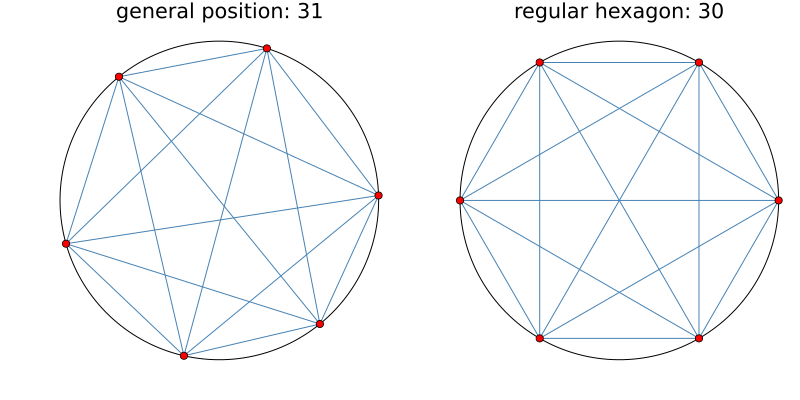

In [5]:
plot(drawchords(angles(6), title = "general position: 31"), drawchords(regular(6), title = "regular hexagon: 30"),
     layout = (1, 2), size = (800, 400))

- $n$ が奇数のときは公式と同じ値になります。正 $n$ 角形で $n$ が奇数なら，3本以上の対角線が内部の1点で交わることはないからです（Poonen–Rubinstein）。
- $n=6$ では中心で3本の対角線が交わり，3つになるはずの交点が1つにまとまるので，領域が1つ減って 30 になります。
- 正 $n$ 角形の対角線の交点の個数と領域の数は，B. Poonen と M. Rubinstein（1998）がすべての $n$ について式を与えています。値は OEIS の A006533 に載っています。

## 6. 発展：球を平面で分ける（3次元版）

**問題**：球面上に $n$ 個の点をとり，3点を選ぶごとにその3点を通る平面をつくる（$\binom{n}{3}$ 枚）。球の内部は最大でいくつの領域に分かれるか。

### OEIS A144841 の経緯

- 2008年，S. Thijssen らが「球面上の $n$ 点の3点ずつを平面で結んだときの最大の領域数の予想値」として OEIS A144841 を登録しました。値は $1, 1, 2, 11, 41, 121, 316, \ldots$ で，式は
$$a(n) = 280\binom{n}{9} + 10\binom{n}{6} + 6\binom{n}{4} + \binom{n}{3} + 1$$
です。
- Math StackExchange（2016年）にも同じ問題の質問があり，質問者は下界として $1 + \binom{n}{3} + 6\binom{n}{4}$（$n=5$ で 41）を予想していましたが，回答はついていません。
- 2025年11月，**青木太一（Taichi Aoki）さん**が OEIS に「数学デー（Sugaku_day）のメンバーが，$n=5$ で 41 ではなく 48 の領域（さらに 54 の領域）ができる例を見つけ，Desmos で可視化した。予想は誤りだった」というコメントを追加しました。Seiichi Manyama さんも，$a(5) = 41$ は小さすぎるようだとコメントしています。
- これを受けて N. J. A. Sloane が編集し，A144841 の名前は**式そのもの**（$a(n) = 280\binom{n}{9}+\cdots$）に変わりました。「球を分ける問題の答え」としての意味は「以前の予想」という扱いになっています（2025年11月15日）。
- 正しい値を並べた数列は，調べた範囲では OEIS にまだありません。

以下では，実際に交わりを正確に計算して領域を数えてみます。

### 数え方：交わりの束とメビウス関数

平面の配置を凸な開集合 $K$（ここでは球の内部）に制限したとき，領域の数は

$$
(\text{領域の数}) = \sum_{X} |\mu(X)|
$$

で求められます（Zaslavsky の定理を凸集合に制限した形）。和は，平面たちの交わりとしてできる**平らな集合 $X$**（空間全体・平面・直線・点）のうち，$K$ と交わるものすべてについてとります。$|\mu(X)|$ は次のように計算できます。

| $X$ | $|\mu(X)|$ |
|---|---|
| 空間全体 | 1 |
| 平面 | 1 |
| $k$ 枚の平面を含む直線 | $k - 1$ |
| $m$ 枚の平面が通る点 | $\left|\,1 - m + \sum_{\ell \ni X} (k_\ell - 1)\,\right|$（$\ell$ はその点を通る交線，$k_\ell$ は $\ell$ を含む平面の枚数） |

**円の場合にあてはめると**：円の内部（$K$）で，全体が 1，弦が 1 本につき 1，交点が 1 個につき 1（2本の弦が交わる点では $|1 - 2| = 1$）なので，$1 + \binom{n}{2} + \binom{n}{4}$ となり，前半の公式と一致します。

**球の場合のむずかしさ**：
- 2点 $A, B$ を通る直線 $AB$ は，$A, B$ を含む $n-2$ 枚の平面すべてに含まれるので $|\mu| = n - 3$ になります。
- 3枚の平面の交点や，共通の点をもたない2枚の平面の交線が**球の内部にあるかどうかは点の配置によって変わります**。そのため，円の場合のように $n$ だけで決まる公式にはなりません。

座標を有理数にすれば，すべての計算を誤差なく行えます。球面上の有理点は，平面上の有理点 $(u, v)$ を逆立体射影
$$(u, v) \mapsto \left(\frac{2u}{u^2+v^2+1},\ \frac{2v}{u^2+v^2+1},\ \frac{u^2+v^2-1}{u^2+v^2+1}\right)$$
で球面に移すと作れます。

In [6]:
using LinearAlgebra
const Q = Rational{BigInt}
const V3 = NTuple{3,Q}
dot3(a, b) = a[1]*b[1] + a[2]*b[2] + a[3]*b[3]
cross3(a, b) = (a[2]*b[3] - a[3]*b[2], a[3]*b[1] - a[1]*b[3], a[1]*b[2] - a[2]*b[1])
sub3(a, b) = (a[1] - b[1], a[2] - b[2], a[3] - b[3])
lead(v) = v[findfirst(!iszero, v)]                     # 最初の 0 でない成分（向きをそろえるため）
sph(u, v) = (u = Q(u); v = Q(v); s = u^2 + v^2 + 1; (2u/s, 2v/s, (u^2 + v^2 - 1)/s))   # 逆立体射影

# 球面上の点 P の3点ずつを通る平面で，球の内部がいくつに分かれるか
function ballregions(P::Vector{V3})
    n = length(P)
    planes = Tuple{V3,Q}[]                              # 平面 n・x = d（n の最初の成分を 1 にそろえる）
    for i in 1:n, j in i+1:n, k in j+1:n
        nv = cross3(sub3(P[j], P[i]), sub3(P[k], P[i]))
        c = lead(nv)
        push!(planes, (nv ./ c, dot3(nv, P[i]) / c))
    end
    unique!(planes)
    m = length(planes)
    onplane(h, x) = dot3(h[1], x) == h[2]
    # 交線：方向 u と，原点にいちばん近い点 p0 で表す。球の内部と交わるものだけ残す
    lines = Dict{Tuple{V3,V3},Int}()                    # 直線 => それを含む平面の枚数
    for a in 1:m, b in a+1:m
        (n1, d1), (n2, d2) = planes[a], planes[b]
        u = cross3(n1, n2)
        all(iszero, u) && continue
        g11, g12, g22 = dot3(n1, n1), dot3(n1, n2), dot3(n2, n2)
        D = g11*g22 - g12^2
        p0 = ((d1*g22 - d2*g12)/D) .* n1 .+ ((d2*g11 - d1*g12)/D) .* n2
        dot3(p0, p0) < 1 || continue
        key = (u ./ lead(u), p0)
        haskey(lines, key) || (lines[key] = count(h -> onplane(h, p0) && iszero(dot3(h[1], u)), planes))
    end
    # 3枚の平面の交点のうち，球の内部にあるもの
    points = Set{V3}()
    for a in 1:m, b in a+1:m, c in b+1:m
        M = Q[collect(planes[a][1])'; collect(planes[b][1])'; collect(planes[c][1])']
        iszero(det(M)) && continue
        x = Tuple(M \ Q[planes[a][2], planes[b][2], planes[c][2]])
        dot3(x, x) < 1 && push!(points, x)
    end
    total = 1 + m + sum(k - 1 for k in values(lines); init = 0)
    for x in points
        mx = count(h -> onplane(h, x), planes)
        s = sum(k - 1 for ((u, p0), k) in lines if all(iszero, cross3(sub3(x, p0), u)); init = 0)
        total += abs(1 - mx + s)
    end
    return total
end

ballregions (generic function with 1 method)

### $n = 1, \ldots, 5$：でたらめな配置で数える

点をでたらめに（有理点で）とって，それぞれ 200 通りの配置で数えます。

In [7]:
using Random
rng = MersenneTwister(2025)
randpoint() = sph(rand(rng, -40:40)//rand(rng, 5:13), rand(rng, -40:40)//rand(rng, 5:13))
randpoints(n) = (S = Set{V3}(); while length(S) < n; push!(S, randpoint()); end; collect(S))

for n in 1:5
    vals = [ballregions(randpoints(n)) for _ in 1:200]
    println("n = $n : ", sort(unique(vals)), "    （OEIS A144841 の旧予想 ", 280binomial(n,9) + 10binomial(n,6) + 6binomial(n,4) + binomial(n,3) + 1, "）")
end

n = 1 : [1]    （OEIS A144841 の旧予想 1）
n = 2 : [1]    （OEIS A144841 の旧予想 1）
n = 3 : [2]    （OEIS A144841 の旧予想 2）
n = 4 : [11]    （OEIS A144841 の旧予想 11）
n = 5 : [54]    （OEIS A144841 の旧予想 41）


$n = 5$ では，どの配置でも **54** になりました。内訳は次のとおりです。

| 平らな集合 | 個数 | $|\mu|$ | 寄与 |
|---|---|---|---|
| 空間全体 | 1 | 1 | 1 |
| 平面 | $\binom{5}{3} = 10$ | 1 | 10 |
| 2点を通る直線 $AB$（3枚の平面を含む） | $\binom{5}{2} = 10$ | 2 | 20 |
| 1点だけ共有する2平面の交線（例：$ABC \cap ADE$） | 15 | 1 | 15 |
| 直線 $AB$ と平面 $CDE$ の交点（4枚の平面が通る） | **4** | 2 | 8 |
| 合計 | | | **54** |

直線 $AB$ と平面 $CDE$ の交点が球の内部にあるのは，$A$ と $B$ が平面 $CDE$ の反対側にあるときです。
5点 $P_1, \ldots, P_5$ にはアフィン従属関係 $\sum \lambda_i P_i = 0$，$\sum \lambda_i = 0$ がただ1つ（定数倍を除いて）あります。$P_A$ と $P_B$ が平面 $CDE$ の反対側にあるのは，$\lambda_A$ と $\lambda_B$ が同じ符号のときです。
球面上の5点は凸の位置にある（どの点も他の4点の四面体の内部にない）ので，$\lambda$ の符号は「正2個・負3個」（またはその逆）になります。よって同じ符号の組は $\binom{2}{2} + \binom{3}{2} = 4$ 組で，どの配置でも 4 になります。

これを確かめます。

In [8]:
# 5点のうち「直線 AB が残り3点の平面と球の内部で交わる」組の数
function crossingchords(P)
    cnt = 0
    for (i, j) in [(i, j) for i in 1:5 for j in i+1:5]
        c, d, e = setdiff(1:5, (i, j))
        nv = cross3(sub3(P[d], P[c]), sub3(P[e], P[c]))
        si = sign(dot3(nv, sub3(P[i], P[c])))
        sj = sign(dot3(nv, sub3(P[j], P[c])))
        cnt += si * sj < 0
    end
    return cnt
end
println("200 通りの配置での個数: ", unique([crossingchords(randpoints(5)) for _ in 1:200]))

200 通りの配置での個数: [4]


したがって，**一般の位置にある5点では必ず 54 個**の領域ができ，OEIS の旧予想 41 は誤りです。

一方，4点が同じ平面上にあるなど**特別な配置**では，平面や交点が重なって領域は 54 より少なくなります。

### $n = 6$：配置によって変わる

$n = 6$ では，平面どうしの交線や3枚の平面の交点が球の内部に入るかどうかが配置によって変わるので，領域の数も変わります。

In [9]:
N, S = (Q(0), Q(0), Q(1)), (Q(0), Q(0), Q(-1))
tri = [(Q(1), Q(0), Q(0)), (Q(-3//5), Q(4//5), Q(0)), (Q(-3//5), Q(-4//5), Q(0))]   # 赤道上の3点
sq  = [(Q(1), Q(0), Q(0)), (Q(0), Q(1), Q(0)), (Q(-1), Q(0), Q(0)), (Q(0), Q(-1), Q(0))]  # 赤道上の正方形
println("両極 + 赤道上の3点（三角両錐）: ", ballregions([N, S, tri...]))
println("北極 + 赤道上の正方形（四角錐）: ", ballregions([N, sq...]))
println("三角両錐の極を1つずらす:         ", ballregions([N, sph(1//7, -3), tri...]))

両極 + 赤道上の3点（三角両錐）: 52
北極 + 赤道上の正方形（四角錐）: 24
三角両錐の極を1つずらす:         54


In [10]:
@time vals6 = [ballregions(randpoints(6)) for _ in 1:40]
println("n = 6（でたらめな配置 40 通り）: 最小 ", minimum(vals6), "，最大 ", maximum(vals6))
println("OEIS A144841 の旧予想: ", 10binomial(6,6) + 6binomial(6,4) + binomial(6,3) + 1)

  4.501702 seconds (81.47 M allocations: 2.717 GiB, 19.65% gc time, 0.25% compilation time)
n = 6（でたらめな配置 40 通り）: 最小 280，最大 303
OEIS A144841 の旧予想: 121


配置を少しずつ動かして領域が増える方向へ進む（山登り法）と，次の配置で **306** 個の領域ができました。
これは最大値の**下界**で，本当の最大値はまだわかりません。

In [11]:
# 山登り法で見つけた配置（立体射影の座標 (u, v)）
uv = [(-3.0934670629539807, 1.2670043430018134), (3.3441723041658236, 0.5974261177769044),
      (-0.049516549409409874, 3.8696524657889264), (1.151780156055776, -2.701617606789911),
      (0.005642259706952327, 3.8377074386002246), (-0.3373396661563572, -1.3328845666662883)]
P6 = [sph(rationalize(BigInt, u, tol = 1e-6), rationalize(BigInt, v, tol = 1e-6)) for (u, v) in uv]
println("領域の数: ", ballregions(P6))

領域の数: 306


### 検算 1：平面を1枚ずつ加える

メビウス関数を使わない別の方法でも数えます。平面を1枚ずつ加えると，新しい平面の「球の内部にある円板」は，それまでの平面との交線によっていくつかの部分に分かれます。各部分が領域を1つずつ2つに分けるので，

$$(\text{増える領域}) = (\text{円板が分かれる個数}) = 1 + (\text{円板と交わる交線の本数}) + \sum_{\text{円板内の交点}} (\text{その点を通る交線の本数} - 1)$$

です（これは前半の円の場合の数え方そのものです）。

In [12]:
function incregions(P::Vector{V3})
    n = length(P)
    planes = Tuple{V3,Q}[]
    for i in 1:n, j in i+1:n, k in j+1:n
        nv = cross3(sub3(P[j], P[i]), sub3(P[k], P[i]))
        c = lead(nv)
        push!(planes, (nv ./ c, dot3(nv, P[i]) / c))
    end
    unique!(planes)
    total = 1
    for k in eachindex(planes)
        nk, dk = planes[k]
        # 平面 k 上の交線（それまでの平面との交わり）で，球の内部と交わるもの
        L = Set{Tuple{V3,V3}}()
        for a in 1:k-1
            n1, d1 = planes[a]
            u = cross3(nk, n1)
            all(iszero, u) && continue
            g11, g12, g22 = dot3(nk, nk), dot3(nk, n1), dot3(n1, n1)
            D = g11*g22 - g12^2
            p0 = ((dk*g22 - d1*g12)/D) .* nk .+ ((d1*g11 - dk*g12)/D) .* n1
            dot3(p0, p0) < 1 && push!(L, (u ./ lead(u), p0))
        end
        L = collect(L)
        # 円板内の交点と，そこを通る交線
        through = Dict{V3,Set{Int}}()
        for a in eachindex(L), b in a+1:length(L)
            (u1, p1), (u2, p2) = L[a], L[b]
            w = cross3(u1, u2)
            all(iszero, w) && continue
            x = p1 .+ (dot3(cross3(sub3(p2, p1), u2), w) / dot3(w, w)) .* u1
            dot3(x, x) < 1 && union!(get!(through, x, Set{Int}()), (a, b))
        end
        total += 1 + length(L) + sum(length(s) - 1 for s in values(through); init = 0)
    end
    return total
end

tests = [randpoints(n) for n in 3:6 for _ in 1:10]
println("ランダムな配置 40 通りで2つの方法が一致: ", all(P -> ballregions(P) == incregions(P), tests))
println("306 の配置: ", ballregions(P6), " と ", incregions(P6))

ランダムな配置 40 通りで2つの方法が一致: true
306 の配置: 306 と 306


### 検算 2：モンテカルロ法

球の内部にでたらめに点をばらまき，各点が各平面のどちら側にあるか（符号の列）を記録して，異なる符号の列の個数を数えます。
とても小さな領域は見落とすので，これは領域の数の**下界**です。$n = 5$ では正確な値に近い数が出ますが，306 の配置は近い点を含んでいて細い領域が多いため，かなり少なく出ます。

In [13]:
function mcregions(P, N; rng = MersenneTwister(7))
    n = length(P)
    Pf = [Float64.(p) for p in P]
    H = [(cross(collect(Pf[j] .- Pf[i]), collect(Pf[k] .- Pf[i])), Pf[i]) for i in 1:n for j in i+1:n for k in j+1:n]
    H = [(nv, dot(nv, collect(p))) for (nv, p) in H]
    seen = Set{UInt64}()
    for _ in 1:N
        x = 2 .* rand(rng, 3) .- 1
        sum(abs2, x) < 1 || continue
        key = UInt64(0)
        for (b, (nv, d)) in enumerate(H)
            dot(nv, x) > d && (key |= UInt64(1) << (b - 1))
        end
        push!(seen, key)
    end
    return length(seen)
end

P5 = randpoints(5)
println("n = 5: 正確な値 ", ballregions(P5), "，モンテカルロ ", [mcregions(P5, N) for N in (10^5, 10^6, 10^7)])
println("n = 6: 正確な値 ", ballregions(P6), "，モンテカルロ ", [mcregions(P6, N) for N in (10^5, 10^6, 10^7)])

n = 5: 正確な値 54，モンテカルロ [42, 48, 51]
n = 6: 正確な値 306，モンテカルロ [143, 185, 229]


## 7. $n = 6$ の最大値を調べる

### 内訳を整理する

一般の位置にある6点では，平らな集合の種類と $|\mu|$ は点の組み合わせだけで決まり，「球の内部にあるかどうか」だけが配置によって変わります。

| 平らな集合 | 個数 | $|\mu|$ | 寄与 |
|---|---|---|---|
| 空間全体 | 1 | 1 | 1 |
| 平面 | $\binom{6}{3} = 20$ | 1 | 20 |
| 2点を通る直線 $AB$（4枚の平面を含む） | $\binom{6}{2} = 15$ | 3 | 45 |
| 1点だけ共有する2平面の交線（例：$ABC \cap ADE$） | 90 | 1 | 90 |
| 直線 $AB$ と，$A, B$ を含まない平面 $T$ の交点 | 内部にあるのは **24**（候補 60） | 3 | 72 |
| 共有点のない2平面の交線（例：$ABC \cap DEF$）：$L_0$ | 内部にあるのは 0〜10（候補 10） | 1 | $L_0$ |
| 3平面の一般の交点：$G$ | 内部にあるのは 0〜120（候補 120） | 1 | $G$ |

**直線 $AB$ と平面 $T$ の交点がいつも 24 個である理由**：6点から5点を選ぶ $\binom{6}{5} = 6$ 通りそれぞれで，$n = 5$ のときと同じ理由（アフィン従属関係の符号が正2個・負3個）により，ちょうど 4 個が内部にあります。$6 \times 4 = 24$ です。

したがって
$$
R(6) = 156 + 72 + L_0 + G = 228 + L_0 + G
$$
です。

**3平面の一般の交点 $G$ の構造**：3枚の平面がどの2枚も1点だけを共有し，3枚に共通の点がないとき，共有される3点を $p, q, r$，残りの3点を $s, t, u$ とすると，平面は $\{p, q, x\}, \{p, r, y\}, \{q, r, z\}$（$\{x, y, z\} = \{s, t, u\}$）の形になります。
6点を $\{p,q,r\} \mid \{s,t,u\}$ に分ける方法が 20 通り，$x, y, z$ の割り当てが 6 通りなので，候補は 120 個です。
また，分け方 $\{p,q,r\} \mid \{s,t,u\}$ と，その左右を入れかえた分け方の対（10 組）には，$L_0$ の直線（平面 $pqr$ と平面 $stu$ の交線）がちょうど1本ずつ対応します。

この内訳を使うと，交点の座標を浮動小数点で計算して「内部かどうか」を判定するだけで数えられるので，正確な計算の数百倍速くなります。

In [14]:
using Combinatorics
const F3 = NTuple{3,Float64}
fdot(a, b) = a[1]*b[1] + a[2]*b[2] + a[3]*b[3]
fcross(a, b) = (a[2]*b[3] - a[3]*b[2], a[3]*b[1] - a[1]*b[3], a[1]*b[2] - a[2]*b[1])
fsub(a, b) = (a[1] - b[1], a[2] - b[2], a[3] - b[3])
const TR = collect(combinations(1:6, 3))                # 20 枚の平面（3点の組）
fplane(P, t) = (nv = fcross(fsub(P[t[2]], P[t[1]]), fsub(P[t[3]], P[t[1]])); (nv, fdot(nv, P[t[1]])))

# 2平面の交線が球の内部を通るか
function lineinside(h1, h2)
    (n1, d1), (n2, d2) = h1, h2
    g11, g12, g22 = fdot(n1, n1), fdot(n1, n2), fdot(n2, n2)
    D = g11*g22 - g12^2
    p0 = ((d1*g22 - d2*g12)/D) .* n1 .+ ((d2*g11 - d1*g12)/D) .* n2
    return fdot(p0, p0) < 1
end

# 3平面の交点が球の内部にあるか
function pointinside(h1, h2, h3)
    (n1, d1), (n2, d2), (n3, d3) = h1, h2, h3
    c23 = fcross(n2, n3)
    x = (d1 .* c23 .+ d2 .* fcross(n3, n1) .+ d3 .* fcross(n1, n2)) ./ fdot(n1, c23)
    return fdot(x, x) < 1
end

# 6点の内訳：CP（直線 AB と平面 T の交点），L0，G と，G を「共有点 {p,q,r}」ごとに数えたもの
function parts6(P::Vector{F3})
    H = [fplane(P, t) for t in TR]
    CP = 0
    for i in 1:6, j in i+1:6, c in 1:20
        (i in TR[c] || j in TR[c]) && continue
        nv, d = H[c]
        (fdot(nv, P[i]) - d) * (fdot(nv, P[j]) - d) < 0 && (CP += 1)
    end
    L0 = count(lineinside(H[a], H[b]) for a in 1:20 for b in a+1:20 if isempty(intersect(TR[a], TR[b])))
    Gby = Dict{Vector{Int},Int}()
    for a in 1:20, b in a+1:20, c in b+1:20
        A, B, C = TR[a], TR[b], TR[c]
        (length(A ∩ B) == 1 && length(A ∩ C) == 1 && length(B ∩ C) == 1 && isempty(A ∩ B ∩ C)) || continue
        pointinside(H[a], H[b], H[c]) || continue
        key = sort(vcat(A ∩ B, A ∩ C, B ∩ C))
        Gby[key] = get(Gby, key, 0) + 1
    end
    return (CP = CP, L0 = L0, G = sum(values(Gby); init = 0), Gby = Gby)
end

fastregions6(P) = (q = parts6(P); 156 + 3q.CP + q.L0 + q.G)

# 正確な計算と一致するか確かめる
toF(P) = [Float64.(p) for p in P]
tests6 = [randpoints(6) for _ in 1:20]
println("正確な計算と一致: ", all(P -> ballregions(P) == fastregions6(toF(P)), tests6))
println("CP の値: ", unique([parts6(toF(P)).CP for P in tests6]))

正確な計算と一致: true
CP の値: [24]


### 焼きなまし法で探す

点を1つ選んで少し動かし，領域が増えれば採用，減っても温度に応じた確率で採用する（焼きなまし法）ことをくり返します。
見つかった配置は，有理数に直して正確な計算でも確かめます。

In [15]:
unitvec(v) = v ./ sqrt(fdot(v, v))

function anneal6(rng; restarts = 3, steps = 15000)
    best, bestP = 0, F3[]
    for _ in 1:restarts
        P = [unitvec((randn(rng), randn(rng), randn(rng))) for _ in 1:6]
        v, temp = fastregions6(P), 3.0
        for step in 1:steps
            i = rand(rng, 1:6)
            σ = 0.3 * exp(-step / 3000) + 1e-3
            P2 = copy(P)
            P2[i] = unitvec(P[i] .+ σ .* (randn(rng), randn(rng), randn(rng)))
            # 近すぎる2点は避ける（浮動小数点の誤差を避けるため）
            minimum(fdot(fsub(P2[a], P2[b]), fsub(P2[a], P2[b])) for a in 1:6 for b in a+1:6) < 1e-4 && continue
            v2 = fastregions6(P2)
            if v2 >= v || rand(rng) < exp((v2 - v) / temp)
                P, v = P2, v2
            end
            temp *= 0.9997
            v > best && ((best, bestP) = (v, copy(P)))
        end
    end
    return best, bestP
end

@time best6, bestP6 = anneal6(MersenneTwister(1))
# 単位ベクトル → 立体射影の座標 → 有理数 → 球面上の有理点
toQ(P) = [sph(rationalize(BigInt, p[1]/(1 - p[3]), tol = 1e-12), rationalize(BigInt, p[2]/(1 - p[3]), tol = 1e-12)) for p in P]
println("焼きなまし法の最大: ", best6, "，正確な計算: ", ballregions(toQ(bestP6)))
q6 = parts6(bestP6)
println("内訳: CP = ", q6.CP, "，L0 = ", q6.L0, "，G = ", q6.G)

 24.981099 seconds (1.13 G allocations: 75.862 GiB, 13.37% gc time, 0.45% compilation time)
焼きなまし法の最大: 306，正確な計算: 306
内訳: CP = 24，L0 = 10，G = 68


4 つの異なる乱数の種でそれぞれ 5 分ずつ（約 50 万配置ずつ）探しても，すべて数秒で 306 に達し，それ以上にはなりませんでした。
306 の配置では，どれも $L_0 = 10$（最大），$G = 68$ です。

### 上界を考える

**証明できる上界**：$L_0 \le 10$，$G \le 120$ なので
$$R(6) \le 228 + 10 + 120 = 358.$$

**観察からの上界（未証明）**：分け方の対（10 組）ごとに「$L_0$ の直線が内部なら 1」と「その対の 12 個の候補のうち内部にある $G$ の個数」を足した値を調べます。
$$R(6) = 228 + \sum_{\text{10 組の対}} \bigl(L_0 \text{ の直線（0 か 1）} + \text{対の } G\bigr)$$

In [16]:
# 分け方の対ごとの値（L0 の直線 + 対の G）
function pairvalues(P)
    q = parts6(P)
    H = [fplane(P, t) for t in TR]
    vals = Tuple{Int,Int}[]
    for s in combinations(1:6, 3)
        1 in s || continue
        sc = setdiff(1:6, s)
        g = get(q.Gby, s, 0) + get(q.Gby, sc, 0)
        l = lineinside(H[findfirst(==(s), TR)], H[findfirst(==(sc), TR)])
        push!(vals, (l, g))
    end
    return vals
end

rng = MersenneTwister(3)
gs, totals = Int[], Int[]
for _ in 1:3000
    for (l, g) in pairvalues([unitvec((randn(rng), randn(rng), randn(rng))) for _ in 1:6])
        push!(gs, g); push!(totals, l + g)
    end
end
println("対の G の値:          ", sort(unique(gs)))
println("対の値（L0 + G）の値: ", sort(unique(totals)))
println("306 の配置での対の値:  ", sort([l + g for (l, g) in pairvalues(bestP6)]))

対の G の値:          [3, 5, 7, 9]
対の値（L0 + G）の値: [4, 5, 6, 7, 8, 9, 10]
306 の配置での対の値:  [6, 6, 6, 8, 8, 8, 8, 8, 10, 10]


- でたらめな配置（3000 通り × 10 組）でも，1組の対の値だけを最大にする焼きなまし法でも，**対の値は 10 を超えませんでした**。対の $G$ はいつも**奇数**（3, 5, 7, 9）でした。
- 対の値が 10 以下であることが示せれば
$$R(6) \le 228 + 10 \times 10 = 328$$
です。対の $G$ が奇数であることが示せれば，$G$ は奇数 10 個の和なので偶数になり，$R(6)$ と $L_0$ の偶奇が一致します（306 の配置では $L_0 = 10$）。
- 306 の配置では 10 組の対の値の平均が 7.8 で，すべての対が同時に 10 になることはできないようです。この「対どうしの干渉」が 306 と 328 の差です。

**まとめると**：$n = 6$ の最大値は
$$306 \le \max R(6) \le 358$$
で，観察からは $\le 328$，探索の結果からは **306 が最大**と予想されます。

**証明に向けての注意**：球を保つ射影変換（双曲幾何のクラインモデルの合同変換）は，平面を平面に，球の内部の点を内部の点にうつすので，領域の数を変えません。この変換は 6 次元あるので，6 点の配置（12 次元）は実質 6 次元の自由度しかありません。

### まとめ

| $n$ | 1 | 2 | 3 | 4 | 5 | 6 |
|---|---|---|---|---|---|---|
| このノートブックで求めた値 | 1 | 1 | 2 | 11 | **54** | **306 以上 358 以下**（予想 306） |
| OEIS A144841 の旧予想 | 1 | 1 | 2 | 11 | 41 | 121 |

- $n \le 4$ は配置によらず決まります（$n = 4$ は4枚の平面と6本の弦で $1 + 4 + 6 = 11$）。
- $n = 5$ は一般の位置ならいつも 54 です（特別な配置では 52 や 24 のように減る例があります）。
- $n = 6$ では配置によって領域の数が変わります。探索で見つかった最大は 306 で，証明できる上界は 358，観察からの上界は 328 です。
- $n \ge 6$ では，最大値を求めるには配置の最適化が必要です。円の場合と違って，$n$ だけで決まる公式にはなりません。

## 参考文献

- OEIS A000127：$\binom{n}{4} + \binom{n}{2} + 1$（円をモーザーの方法で分けたときの最大の領域数）. https://oeis.org/A000127
- OEIS A006533：正 $n$ 角形のすべての対角線で円を分けたときの領域数. https://oeis.org/A006533
- B. Poonen, M. Rubinstein, *The Number of Intersection Points Made by the Diagonals of a Regular Polygon*, SIAM J. Discrete Math. **11** (1998), 135–156. https://arxiv.org/abs/math/9508209
- Wikipedia, *Dividing a circle into areas*. https://en.wikipedia.org/wiki/Dividing_a_circle_into_areas
- 3Blue1Brown, *Circle Division Solution*（YouTube）.
- OEIS A144841（旧：球を平面で分けたときの最大領域数の予想）. https://oeis.org/A144841
- Math StackExchange, *Maximum number of regions of a sphere partitioned by binomial(n,3) planes from n points*（2016）. https://math.stackexchange.com/questions/1998893
- 数学デー（Sugaku_day）, *There could exist 48 regions for n=5*（2025年11月12日）. https://x.com/sugaku_day/status/1988617807647391992 ／ *Our member found 54 regions for n=5*（2025年11月20日）. https://x.com/sugaku_day/status/1991160200988946790
- 青木太一, Desmos 3D による $n=5$ の例：48 領域 https://www.desmos.com/3d/2u3gnbfcda ，54 領域 https://www.desmos.com/3d/jswg36j3mn
- T. Zaslavsky, *Facing up to arrangements: face-count formulas for partitions of space by hyperplanes*, Mem. Amer. Math. Soc. **154** (1975).
